# Task 3 Spam detection data analysis
Roman Bukin. This notebook processes actual timed runs of the Task 2 classifiers. The bundled input is **10 synthetic emails only**. Results are a pipeline smoke test, not a completed real-corpus study. Use Restart & Run All to reproduce the analysis from saved logs.

In [1]:
from pathlib import Path
import sys
import numpy as np
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/process_data.py").exists(), "Run from project root or notebooks folder"
sys.path.insert(0, str(ROOT / "src"))
np.random.seed(42)
from process_data import load_data, process
from visualize import plots
from write_report import write_report
print("Project:", ROOT.name)


Project: Task2_Bukin


## Data ingestion and warm-up filtering
The collection command records a full warm-up pass before measured runs. Exclude rows explicitly marked warmup; do not silently discard a fixed number of rows from arbitrary input.

In [2]:
raw, frame = load_data()
print(raw.groupby(["phase", "mode"]).size().to_string())
print("Benchmark rows:", len(frame))
print("Actual training sizes:", sorted(frame.n_train.unique().tolist()))
assert (frame.phase == "benchmark").all()
assert not frame.duplicated(["model", "train_fraction", "seed"]).any()
print(frame[["model", "seed", "n_train", "n_test", "f1", "false_positive_rate"]].head().to_string(index=False))

phase      mode    
benchmark  research    45
warmup     research     9
Benchmark rows: 45
Actual training sizes: [321, 644, 1289]
              model  seed  n_train  n_test       f1  false_positive_rate
        naive_bayes    42      321     323 0.128205                0.000
logistic_regression    42      321     323 0.554455                0.000
      random_forest    42      321     323 0.813008                0.000
        naive_bayes    42      644     323 0.479167                0.000
logistic_regression    42      644     323 0.786885                0.004


## Statistical aggregation
Calculate mean, sample SD, median and p95 across seeds. Compute percentile bootstrap 95% intervals for the mean using 5000 resamples and seed 42. These intervals are conditional on one fixed holdout and are descriptive only. Report classification error and FPR as guardrails. The sample holdout has only two ham emails; a zero observed FPR does not establish the population 5% threshold.

In [3]:
frame, summary = process()
print(summary[["model", "train_fraction", "n_runs", "f1_mean", "f1_ci_low", "f1_ci_high", "false_positive_rate_mean", "classification_error_rate_mean", "fpr_guardrail_pass_all_runs"]].to_string(index=False))
assert len(summary) == frame.groupby(["mode", "model", "train_fraction"]).ngroups
assert (summary.f1_ci_low <= summary.f1_ci_high).all()

Excluded 9 warm-up rows; retained 45 benchmark rows.
              model  train_fraction  n_runs  f1_mean  f1_ci_low  f1_ci_high  false_positive_rate_mean  classification_error_rate_mean  fpr_guardrail_pass_all_runs
logistic_regression            0.25       5 0.567921   0.542602    0.598201                    0.0000                        0.136223                         True
logistic_regression            0.50       5 0.786519   0.766125    0.800629                    0.0040                        0.080495                         True
logistic_regression            1.00       5 0.870229   0.870229    0.870229                    0.0040                        0.052632                         True
        naive_bayes            0.25       5 0.078010   0.042401    0.113620                    0.0000                        0.216718                         True
        naive_bayes            0.50       5 0.472499   0.456550    0.491386                    0.0000                        0.15603

## Visualization and export
Use labeled physical units for timing and unitless labels for F1/FPR. Plot uncertainty, distinguish models with markers and line styles, and export each figure as vector PDF and 300 DPI PNG. Training fraction is not concurrent service load. The first two sample fractions both use two training emails.

Exported 3 figures as vector PDF and 300 DPI PNG.


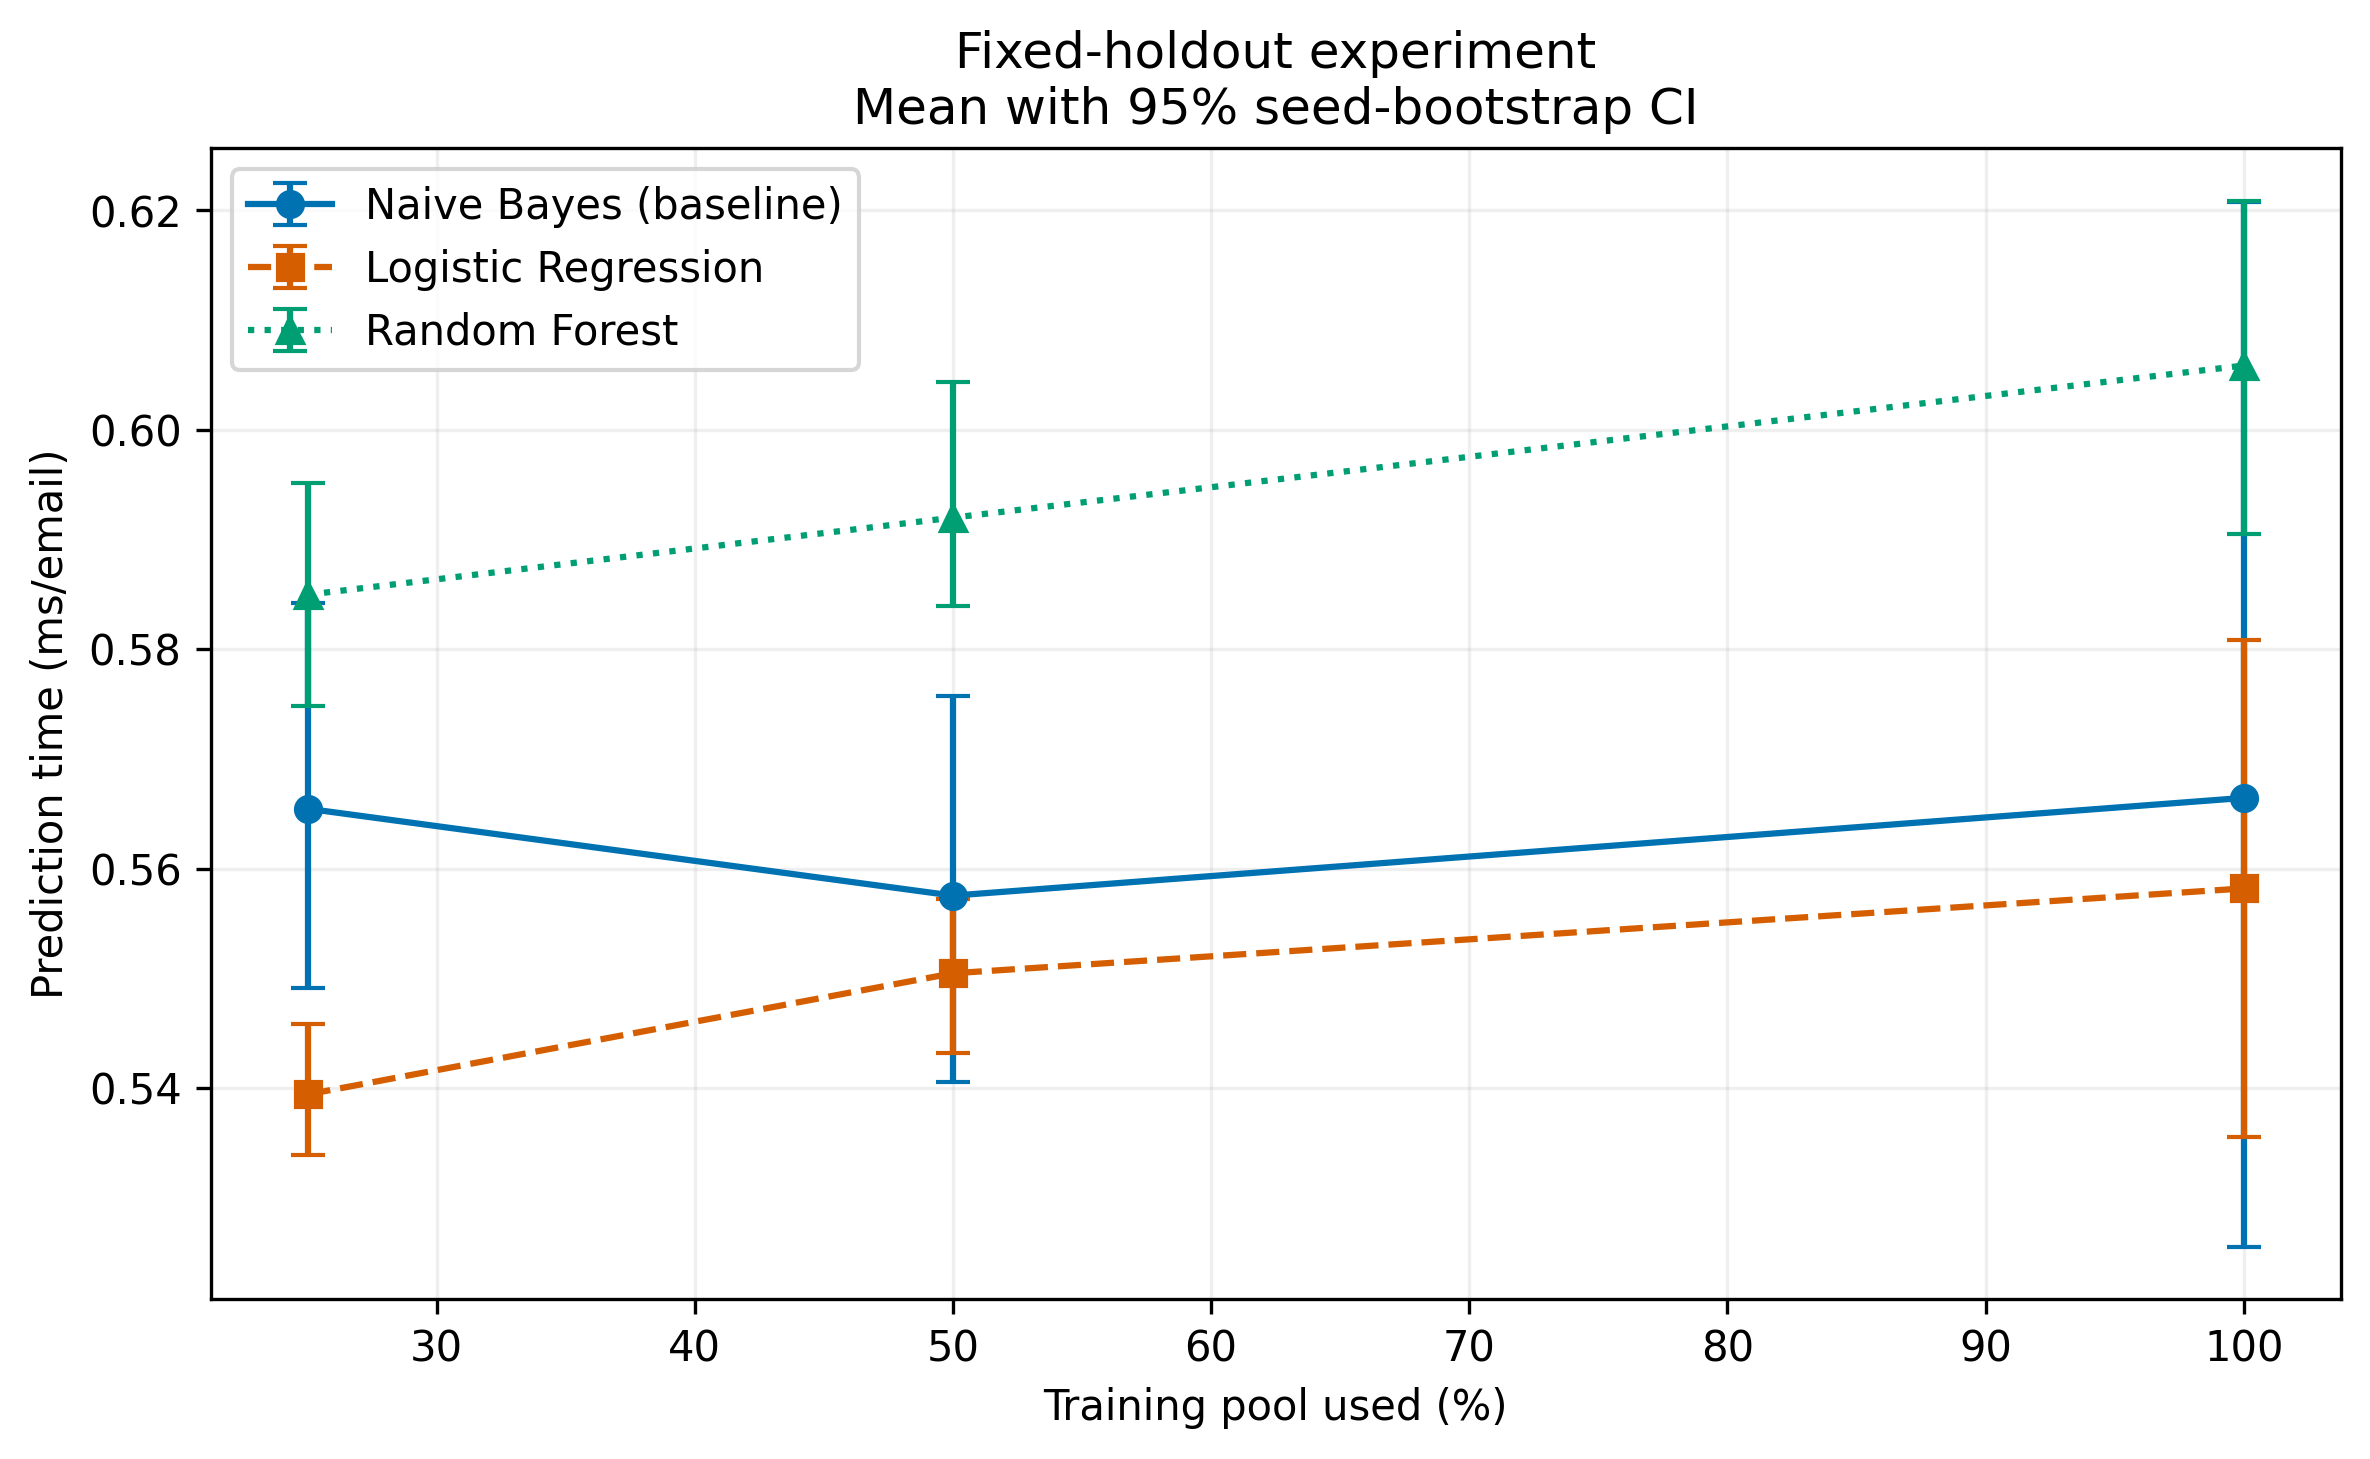

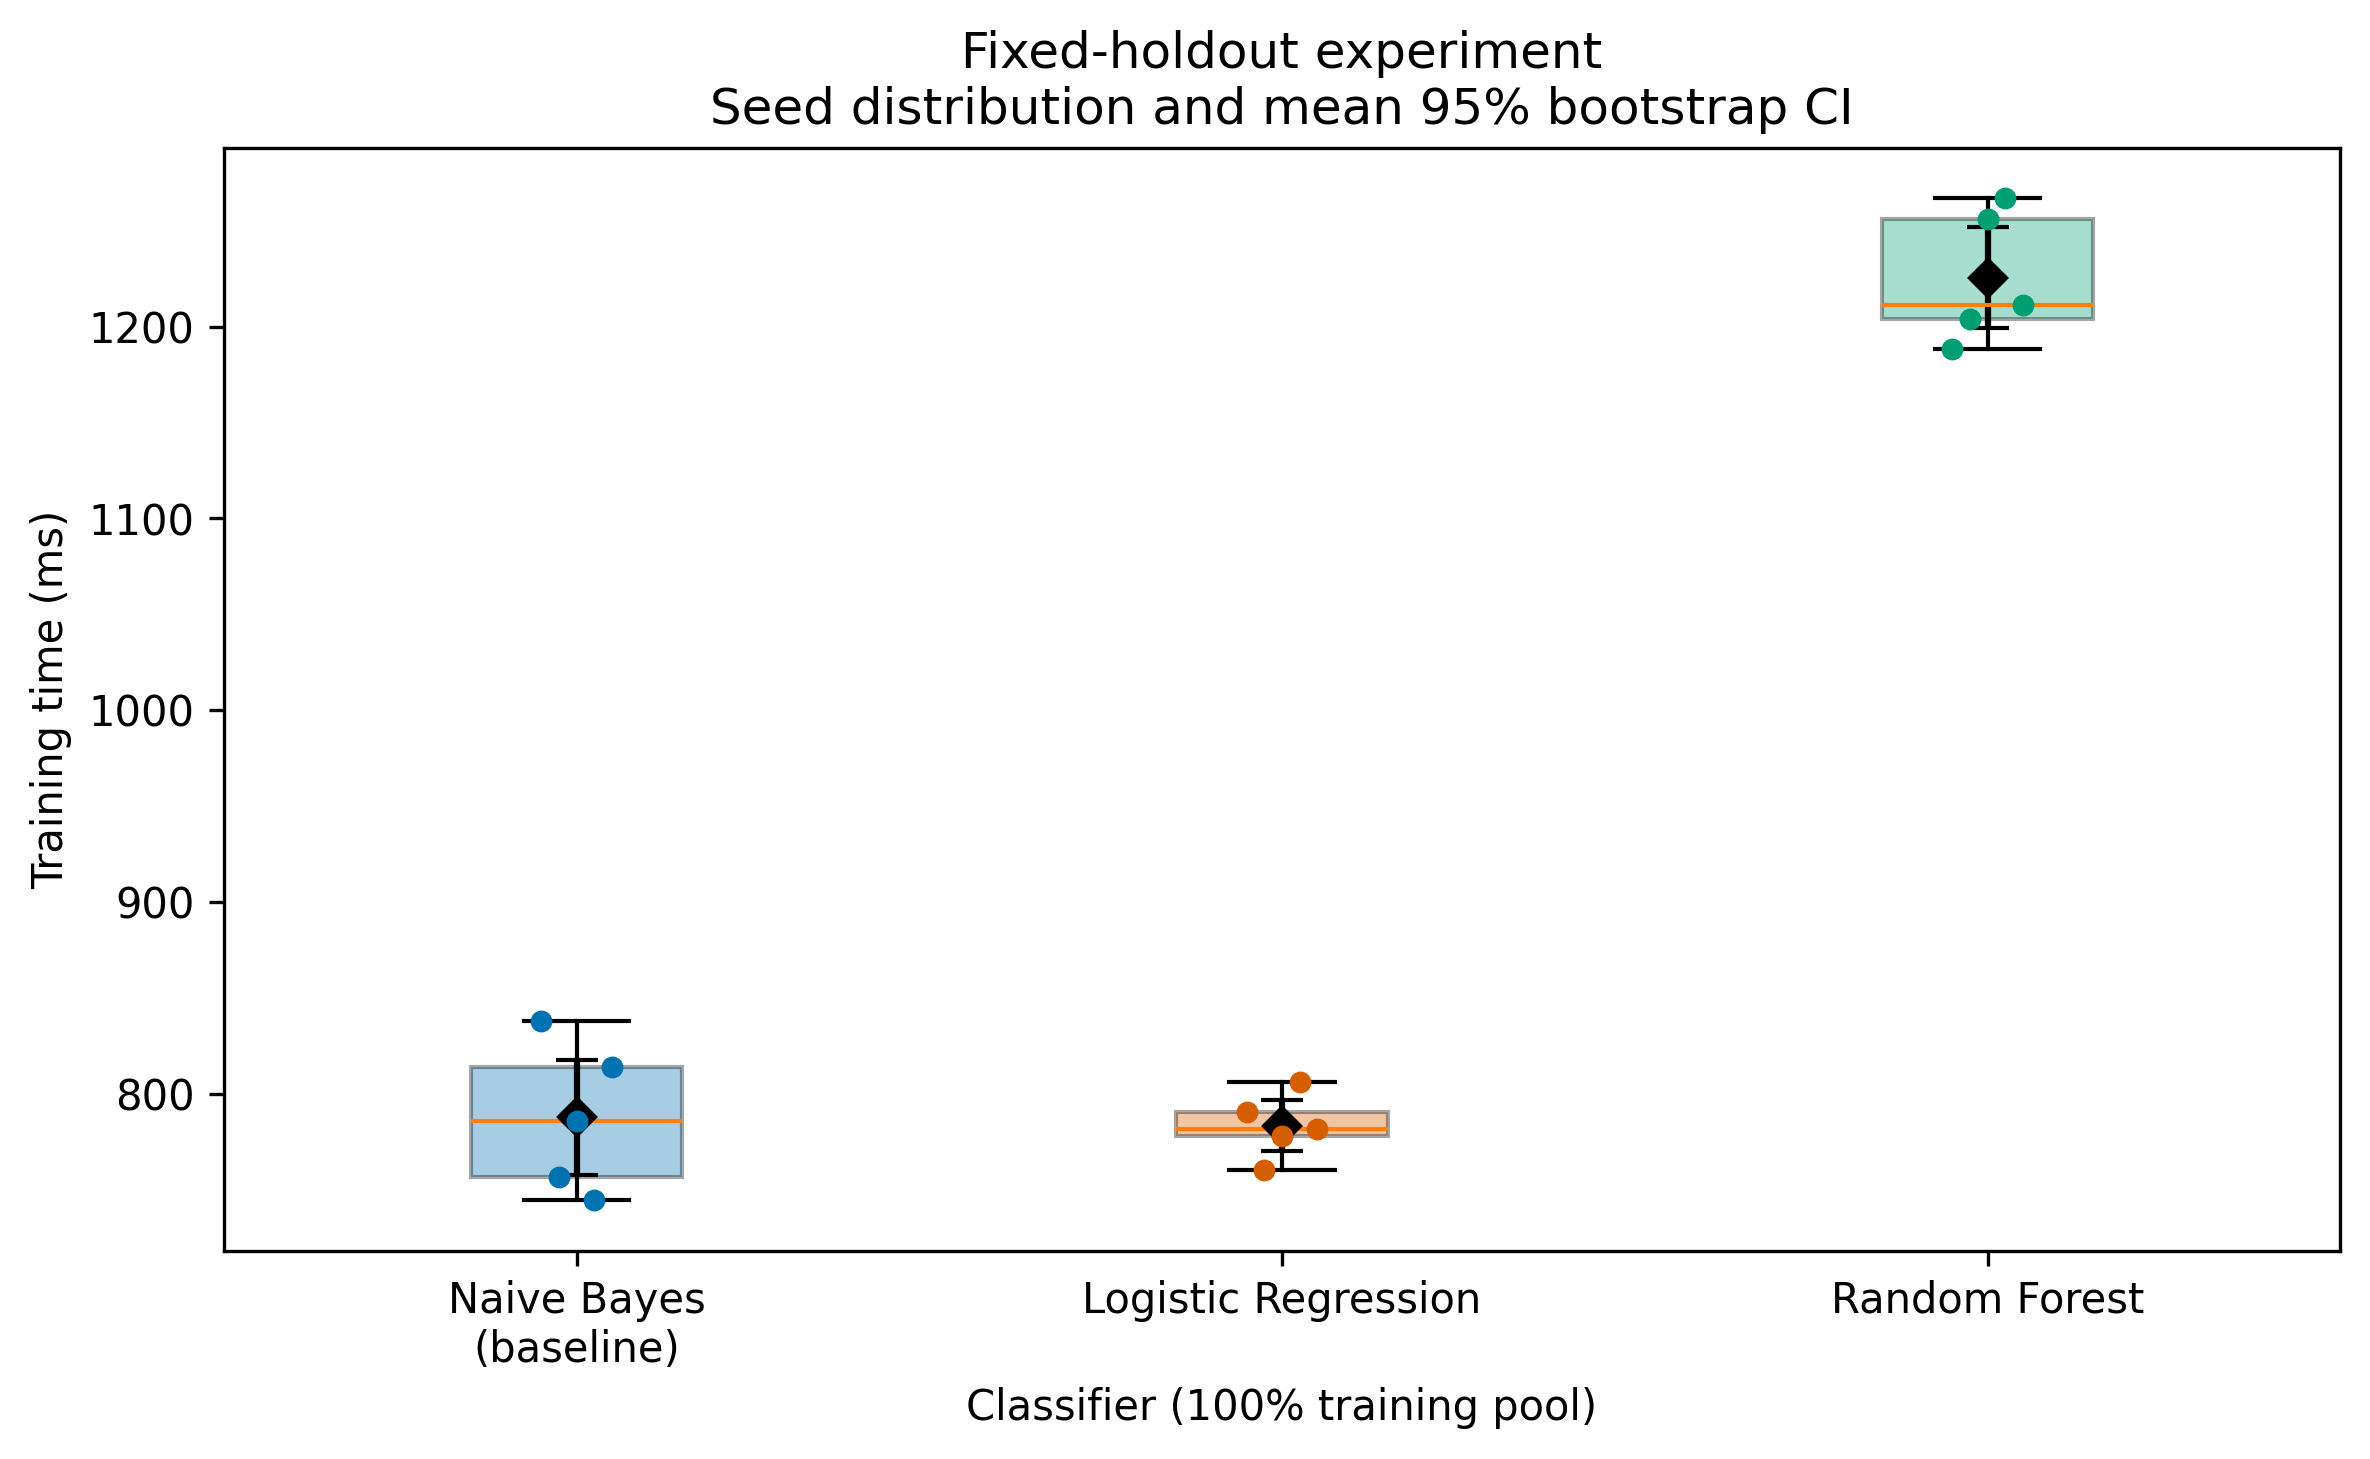

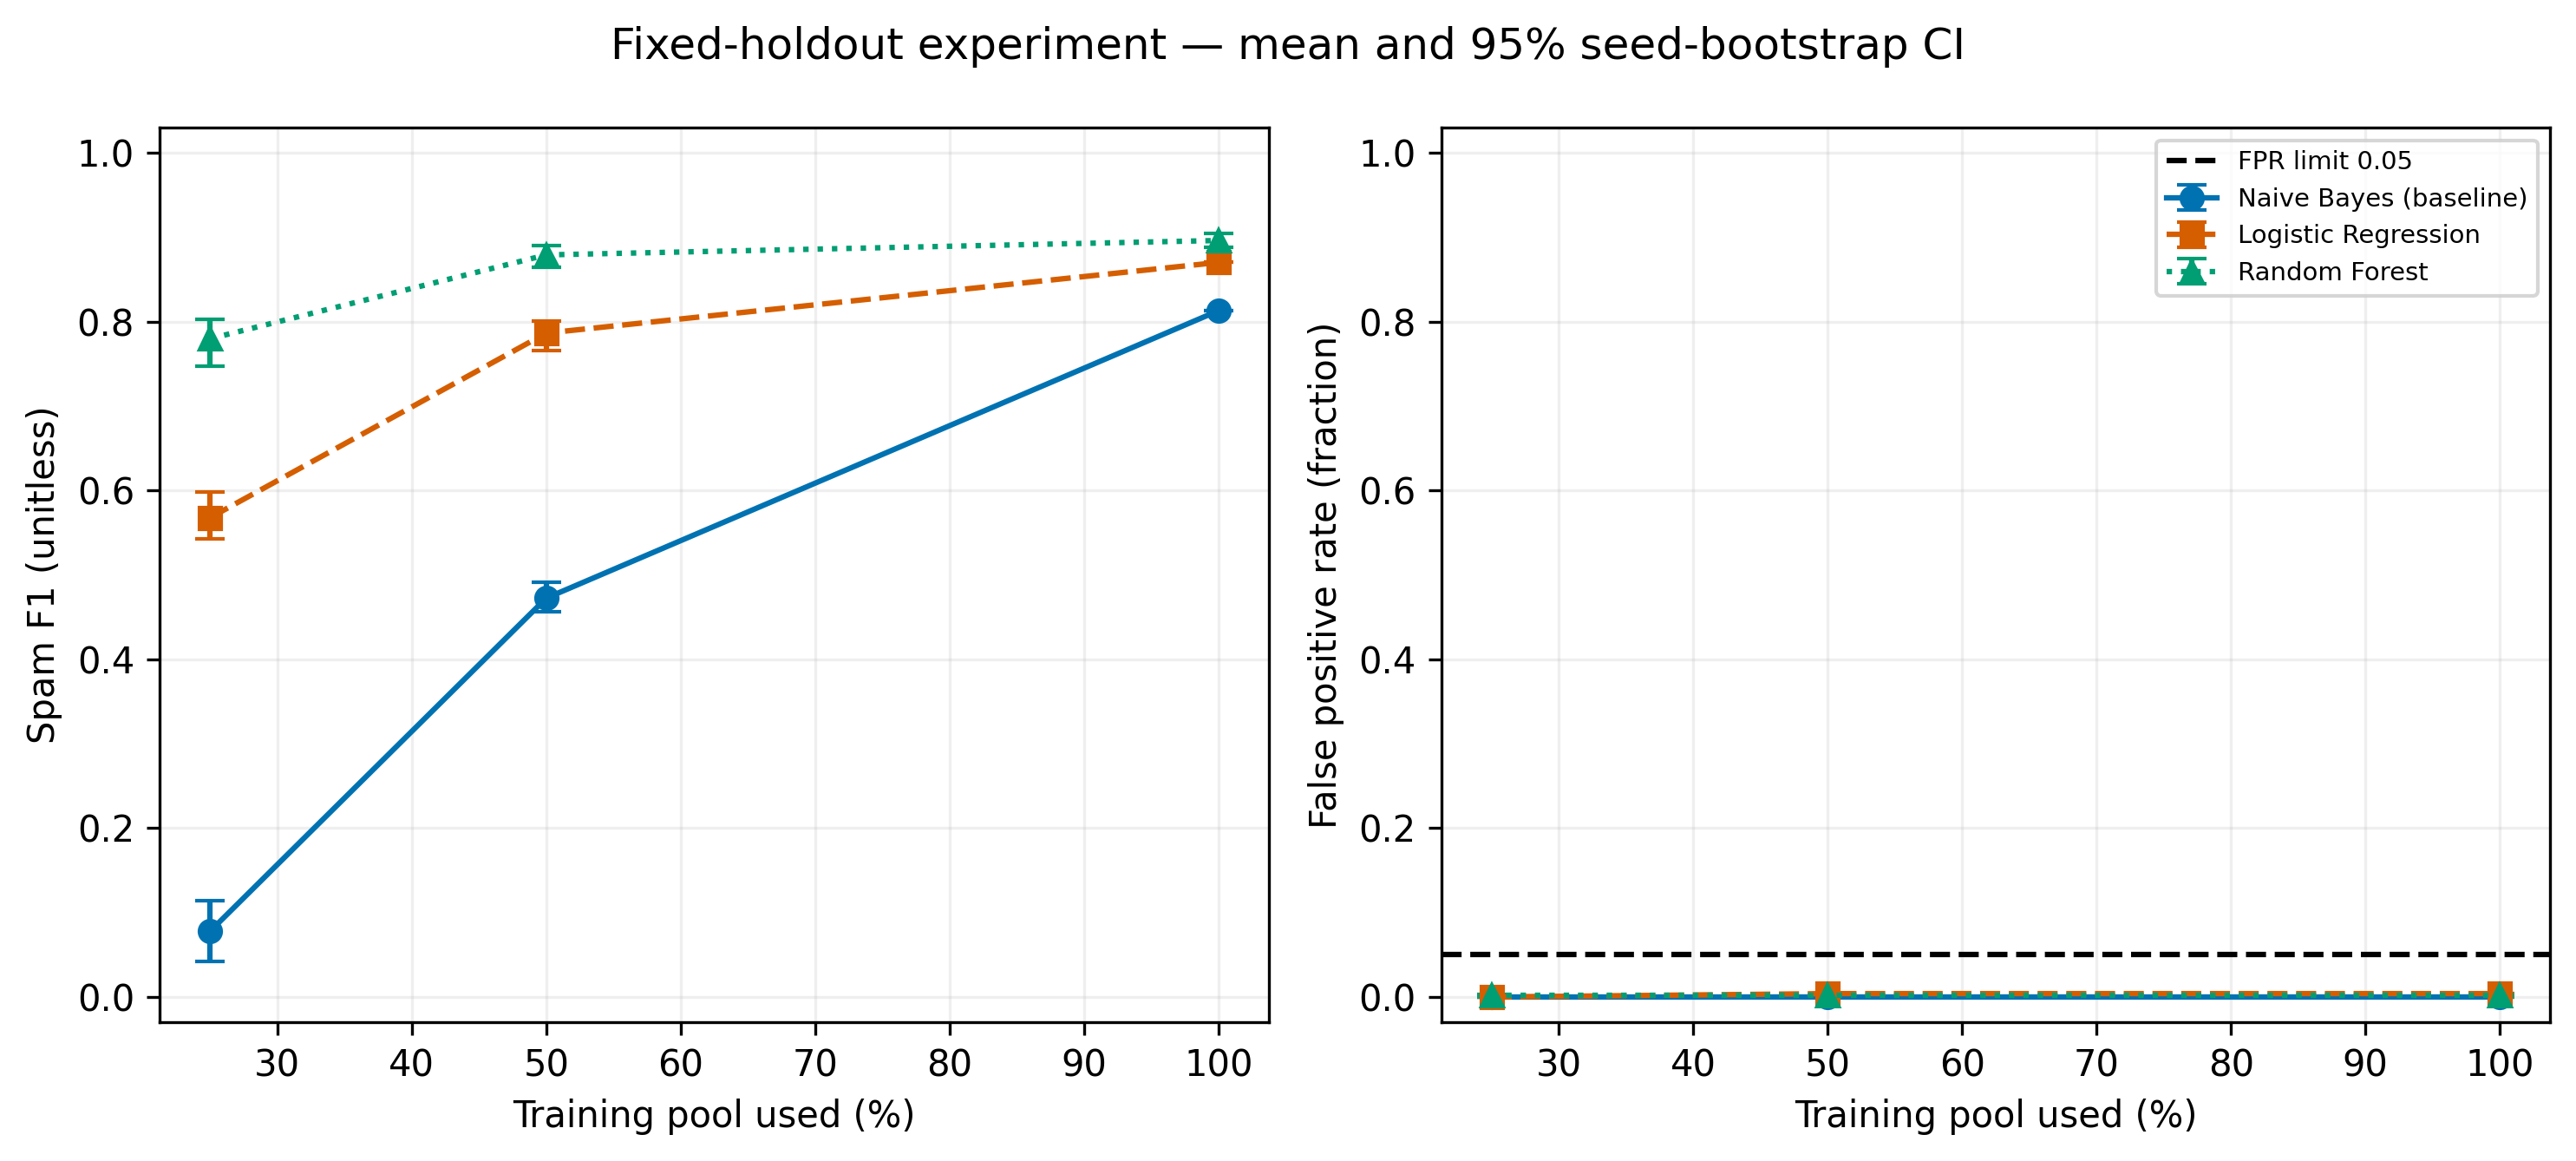

In [4]:
plots(frame, summary)
from IPython.display import Image, display
for name in ["fig1_latency_vs_load", "fig2_distribution_boxplot", "fig3_quality"]:
    assert (ROOT / "reports/figures" / (name + ".pdf")).exists()
    display(Image(filename=str(ROOT / "reports/figures" / (name + ".png")), width=800))

## Interpretation and output
Identical seed scores can have zero-width intervals. Five runs on four shared test emails cannot support a reliable model ranking. The generated report explicitly distinguishes the synthetic check from the still-needed real-data experiment. Timing results depend on the execution environment.

In [5]:
write_report()
print("Saved summary, 6 figure files, README and Markdown report.")

Updated report and README.
Saved summary, 6 figure files, README and Markdown report.
